# Embedding графа знаний: объекты OpenStreetMap проекта аренды

Ноутбук выполняет практикум по KG Embeddings на CPU: проверка данных и разбиения, построение триплетов, обучение TransE, ранговые метрики, кластеризация, классификация и предсказание недостающих связей.

Сначала проверяется, хватает ли объявлений для этих задач. Затем выбирается датасет. Все результаты ниже получены запуском ячеек сверху вниз; числа сохраняются в `results/embedding_metrics.json`.

Запуск из каталога `rental_kg`: `python notebooks/run_notebook.py notebooks/embedding_kg.ipynb` или «Run All» в Jupyter.

In [1]:
import gzip
import json
import math
import platform
import sys
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, adjusted_rand_score, f1_score
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.preprocessing import normalize

SEED = 20261127
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "osm").is_dir())
RESULTS = ROOT / "notebooks" / "results"
RESULTS.mkdir(parents=True, exist_ok=True)
METRICS = {"seed": SEED}
pd.set_option("display.width", 140)

versions = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
}
METRICS["versions"] = versions
print(json.dumps(versions, indent=1))
print("Устройство: CPU, без GPU-библиотек")

{
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v880-x86_64-with-glibc2.39",
 "numpy": "2.5.3",
 "pandas": "3.0.5",
 "scikit-learn": "1.9.1",
 "matplotlib": "3.11.2"
}
Устройство: CPU, без GPU-библиотек


## 1. Достаточно ли объявлений

Кандидат по заданию — сущности графа объявлений. Проверяем число наблюдений, карточек и квартир, повторные наблюдения одной карточки и одной квартиры, даты для временного разбиения и баланс возможных целевых признаков.

Разбиение объявлений должно идти по квартире: все наблюдения и карточки одной квартиры попадают в одну часть. Иначе модель увидит ту же квартиру в обучении и проверке.

In [2]:
def read_csv(path):
    return pd.read_csv(path, dtype=str, keep_default_na=False) if path.exists() else pd.DataFrame()

sources = ROOT / "data" / "sources"
slices = pd.concat([read_csv(p) for p in sorted(sources.glob("*/slice.csv"))], ignore_index=True)
history = pd.concat([read_csv(p) for p in sorted(sources.glob("*/history.csv"))], ignore_index=True)
history["card"] = history["platform"] + ":" + history["source_id"]
# Apartment groups come from the current slices: history keeps older rows unchanged.
slices["card"] = slices["platform"] + ":" + slices["source_id"]
group_of = dict(zip(slices["card"], np.where(slices["verified_home_id"] != "", slices["verified_home_id"], slices["id"])))
history["apartment"] = [group_of.get(card, key) for card, key in zip(history["card"], history["id"])]

per_card = history.groupby("card")["observed_on"].nunique()
per_apartment = history.groupby("apartment")["card"].nunique()
dates = history.groupby("observed_on")["apartment"].nunique()
listing_check = {
    "observations": len(history),
    "cards": history["card"].nunique(),
    "apartments": history["apartment"].nunique(),
    "cards_observed_more_than_once": int((per_card > 1).sum()),
    "apartments_with_several_cards": int((per_apartment > 1).sum()),
    "observation_dates": {k: int(v) for k, v in dates.items()},
    "pets_known": int((history["pets_allowed"] != "").sum()),
    "rooms": {k: int(v) for k, v in history["rooms"].value_counts().sort_index().items()},
}
METRICS["listing_check"] = listing_check
print(json.dumps(listing_check, ensure_ascii=False, indent=1))

# Date split from the practicum, grouped by apartment.
first_seen = history.groupby("apartment")["observed_on"].min()
train_apartments = set(first_seen[first_seen < "2026-11-01"].index)
test_apartments = set(first_seen.index) - train_apartments
print("Квартир до 01.11.2026:", len(train_apartments), "после:", len(test_apartments))
print("Квартиры в обеих частях:", len(train_apartments & test_apartments))

{
 "observations": 11,
 "cards": 11,
 "apartments": 11,
 "cards_observed_more_than_once": 0,
 "apartments_with_several_cards": 0,
 "observation_dates": {
  "2026-10-22": 6,
  "2026-11-26": 5
 },
 "pets_known": 4,
 "rooms": {
  "0": 1,
  "1": 4,
  "2": 3,
  "3": 2,
  "5": 1
 }
}
Квартир до 01.11.2026: 6 после: 5
Квартиры в обеих частях: 0


**Вывод по объявлениям.** Одиннадцать квартир, два дня наблюдения, ни одной повторно наблюдённой карточки и ни одной подтверждённой пары карточек. Временное разбиение даёт 6 квартир в обучении и 5 в проверке, причём это разные срезы (город в октябре и остров в ноябре). Условие о животных известно только у четырёх карточек, и все четыре — запрет: целевого признака с двумя классами нет. На таком наборе классификатор и метрики ранжирования неинформативны: одна ошибка меняет точность на 20 процентных пунктов.

Поэтому учебный датасет отделён от данных сайта. Используются **сущности OSM-части графа проекта**: 294 объекта инфраструктуры Петроградской стороны из снимка от 13.11.2026 (тот же файл, из которого строится `osm_pilot` в графе и маршруты сайта). Объявления в обучение не входят, и результаты не переносятся на сайт.

In [3]:
with gzip.open(ROOT / "data" / "osm" / "osm_pilot.json.gz", "rt", encoding="utf-8") as file:
    snapshot = json.load(file)

features = pd.DataFrame(snapshot["features"])
features["entity"] = features["osm_type"] + "/" + features["osm_id"]
features["lon"] = features["point"].str[0]
features["lat"] = features["point"].str[1]
features["station_ref"] = features["station"].apply(lambda v: "/".join(v) if isinstance(v, list) else "")
print("Снимок:", snapshot["extracted_on"], "объектов:", len(features))
print(features["type"].value_counts().to_string())
print("Без названия:", features["label"].isna().groupby(features["type"]).sum().to_dict())
print("Входов без однозначной станции:", int(((features["type"] == "MetroEntrance") & (features["station_ref"] == "")).sum()))
assert features["entity"].is_unique

Снимок: 2026-11-13 объектов: 294
type
Park             154
Supermarket       93
MetroEntrance     39
MetroStation       8
Без названия: {'MetroEntrance': 1, 'MetroStation': 0, 'Park': 101, 'Supermarket': 0}
Входов без однозначной станции: 5


### Пропуски

Пропуски не заполняются. Если у объекта нет названия, у него нет и триплета `has_name`. Если вход метро не сопоставлен со станцией, нет триплета `entrance_of`. Удалять такие объекты не требуется: у каждого есть координаты, а значит, и пространственные связи.

### Целевой признак и критерий разбиения

Целевой признак — тип объекта OSM: парк, супермаркет, вход метро или станция. Триплеты `rdf:type` в обучение **не включаются**.

В снимке одна дата, поэтому временной порог из практикума неприменим. Используется пространственное разбиение: город делится на ячейки около 450 × 450 м, и ячейки целиком попадают в обучение или проверку. Соседние объекты одной ячейки не оказываются по разные стороны. Seed выбирается до обучения по одному правилу: все четыре класса представлены в обеих частях не менее чем двумя объектами.

In [4]:
LAT_STEP, LON_STEP = 0.004, 0.008  # about 445 m at 60° N
lat0, lon0 = features["lat"].min(), features["lon"].min()
features["cell"] = [
    f"cell_{int((lat - lat0) // LAT_STEP)}_{int((lon - lon0) // LON_STEP)}"
    for lat, lon in zip(features["lat"], features["lon"])
]
cells = sorted(features["cell"].unique())
print("Ячеек с объектами:", len(cells))

def split_cells(seed, share=0.3):
    rng = np.random.default_rng(seed)
    order = rng.permutation(cells)
    return set(order[: round(len(order) * share)])

for attempt in range(100):
    test_cells = split_cells(SEED + attempt)
    part = np.where(features["cell"].isin(test_cells), "test", "train")
    table = pd.crosstab(features["type"], part, colnames=["часть"])
    if (table.min(axis=1) >= 2).all():
        break
features["part"] = part
METRICS["split"] = {
    "seed_offset": attempt,
    "test_cells": len(test_cells),
    "train_cells": len(cells) - len(test_cells),
    "counts": {t: {k: int(v) for k, v in row.items()} for t, row in table.iterrows()},
}
print("Смещение seed:", attempt)
print(table.to_string())

Ячеек с объектами: 95
Смещение seed: 1
часть          test  train
type                      
MetroEntrance    23     16
MetroStation      4      4
Park             47    107
Supermarket      27     66


## 2. Триплеты

Своя логика преобразования (вариант 3.1 практикума). Отношения:

| Отношение | Смысл |
|---|---|
| `in_cell` | объект → ячейка сетки |
| `cell_east_of`, `cell_north_of` | соседние ячейки |
| `entrance_of` | вход метро → станция (из OSM) |
| `has_name` | объект → название; общие названия сетей и станций связывают объекты |
| `nearest_station` | объект → ближайшая станция по геодезическому расстоянию (сферическая формула; для станций не строится) |

`nearest_station` объектов проверочной части убирается из обучения: это задача предсказания связей.

In [5]:
EARTH_M = 6371008.8

def haversine(lon1, lat1, lon2, lat2):
    p1, p2 = math.radians(lat1), math.radians(lat2)
    dp, dl = p2 - p1, math.radians(lon2 - lon1)
    a = math.sin(dp / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(dl / 2) ** 2
    return 2 * EARTH_M * math.asin(math.sqrt(a))

stations = features[features["type"] == "MetroStation"]
station_ids = list(stations["entity"])

triples = []
for row in features.itertuples():
    triples.append((row.entity, "in_cell", row.cell))
    if isinstance(row.label, str):
        triples.append((row.entity, "has_name", "name:" + row.label.casefold()))
    if row.station_ref:
        triples.append((row.entity, "entrance_of", row.station_ref))
    if row.type != "MetroStation":
        nearest = min(stations.itertuples(), key=lambda s: haversine(row.lon, row.lat, s.lon, s.lat))
        triples.append((row.entity, "nearest_station", nearest.entity))
for cell in cells:
    _, i, j = cell.split("_")
    for name, other in (("cell_north_of", f"cell_{int(i) - 1}_{j}"), ("cell_east_of", f"cell_{i}_{int(j) - 1}")):
        if other in cells:
            triples.append((cell, name, other))
triples = sorted(set(triples))

part_of = dict(zip(features["entity"], features["part"]))
link_test = [t for t in triples if t[1] == "nearest_station" and part_of[t[0]] == "test"]
train_triples = [t for t in triples if t not in set(link_test)]
assert not any(r == "type" for _, r, _ in triples)
print(pd.Series(Counter(r for _, r, _ in triples)).to_string())
print("Всего триплетов:", len(triples), "| в обучающей части:", len(train_triples), "| скрыто для link prediction:", len(link_test))

cell_east_of        58
cell_north_of       55
has_name           192
in_cell            294
nearest_station    286
entrance_of         34
Всего триплетов: 919 | в обучающей части: 822 | скрыто для link prediction: 97


## 3. Разбиение триплетов для обучения и оценки embedding

Практикум требует, чтобы каждый узел встречался в обеих частях: обучающей и оценочной. Это возможно только для узлов, у которых в обучающем графе не меньше двух триплетов: одна связь не может лежать в двух частях сразу. Поэтому критерий применяется к **2-ядру** графа. 2-ядро — подграф, который остаётся после многократного удаления узлов с единственной связью.

Узлы вне ядра — в основном уникальные названия и безымянные парки проверочных ячеек, у которых скрыта связь `nearest_station`. Их триплеты остаются только в обучении, и в критерий они не входят. Ниже приведено, сколько таких узлов и триплетов.

Внутри ядра для каждого узла в оценку переносится один инцидентный триплет. Перенос допустим, если у обоих концов и у отношения в обучении остаётся хотя бы одна связь.

In [6]:
rng = np.random.default_rng(SEED)
core = {x for h, _, t in train_triples for x in (h, t)}
while True:
    degree = Counter()
    for h, _, t in train_triples:
        if h in core and t in core:
            degree[h] += 1
            degree[t] += 1
    weak = {x for x in core if degree[x] < 2}
    if not weak:
        break
    core -= weak
core_triples = [tr for tr in train_triples if tr[0] in core and tr[2] in core]
leaf_triples = [tr for tr in train_triples if not (tr[0] in core and tr[2] in core)]

fit_set, evaluation = set(core_triples), []
fit_degree = Counter(x for h, _, t in core_triples for x in (h, t))
fit_relation = Counter(r for _, r, _ in core_triples)
in_eval = set()
incident = defaultdict(list)
for tr in core_triples:
    incident[tr[0]].append(tr)
    incident[tr[2]].append(tr)
for node in rng.permutation(sorted(core)):
    if node in in_eval:
        continue
    options = [
        tr for tr in incident[node]
        if tr in fit_set and fit_degree[tr[0]] > 1 and fit_degree[tr[2]] > 1 and fit_relation[tr[1]] > 1
    ]
    if not options:
        continue
    # Prefer a triple that also covers the other end.
    options.sort(key=lambda tr: (tr[0] in in_eval) + (tr[2] in in_eval))
    h, r, t = options[0]
    fit_set.discard((h, r, t))
    evaluation.append((h, r, t))
    fit_degree[h] -= 1
    fit_degree[t] -= 1
    fit_relation[r] -= 1
    in_eval.update((h, t))
fit = sorted(fit_set) + leaf_triples
evaluation.sort()

entities = sorted({x for h, _, t in triples for x in (h, t)})
relations = sorted({r for _, r, _ in triples})
fit_entities = {x for h, _, t in fit for x in (h, t)}
eval_entities = {x for h, _, t in evaluation for x in (h, t)}
train_entities = {x for h, _, t in train_triples for x in (h, t)}
outside = train_entities - core
coverage = {
    "train_part_triples": len(train_triples),
    "fit_triples": len(fit),
    "eval_triples": len(evaluation),
    "entities_total": len(entities),
    "entities_in_train_part": len(train_entities),
    "core_entities": len(core),
    "core_entities_in_both_parts": len(core & fit_entities & eval_entities),
    "entities_outside_core": len(outside),
    "outside_core_by_kind": dict(sorted(Counter(
        "название" if x.startswith("name:") else "ячейка" if x.startswith("cell_") else part_of.get(x, "?")
        for x in outside
    ).items())),
    "leaf_triples_fit_only": len(leaf_triples),
    "relations_in_both_parts": sorted({r for _, r, _ in evaluation} & {r for _, r, _ in fit}),
    "eval_entities_seen_in_fit": len(eval_entities & fit_entities) / len(eval_entities),
}
METRICS["embedding_split"] = coverage
print(json.dumps(coverage, ensure_ascii=False, indent=1))
assert coverage["core_entities_in_both_parts"] == coverage["core_entities"]

{
 "train_part_triples": 822,
 "fit_triples": 567,
 "eval_triples": 255,
 "entities_total": 465,
 "entities_in_train_part": 465,
 "core_entities": 350,
 "core_entities_in_both_parts": 350,
 "entities_outside_core": 115,
 "outside_core_by_kind": {
  "test": 51,
  "train": 2,
  "название": 57,
  "ячейка": 5
 },
 "leaf_triples_fit_only": 114,
 "relations_in_both_parts": [
  "cell_east_of",
  "cell_north_of",
  "entrance_of",
  "has_name",
  "in_cell",
  "nearest_station"
 ],
 "eval_entities_seen_in_fit": 1.0
}


## 4. Модель TransE на NumPy

TransE представляет отношение как сдвиг: для верного триплета `h + r ≈ t`. Оценка триплета — `−‖h + r − t‖`. Обучение — маржинальная функция потерь с отрицательными примерами, полученными заменой головы или хвоста случайной сущностью. Реализация на NumPy занимает несколько секунд на CPU и полностью воспроизводима при фиксированном seed.

Потери: эпоха 1 = 0.992, эпоха 300 = 0.054


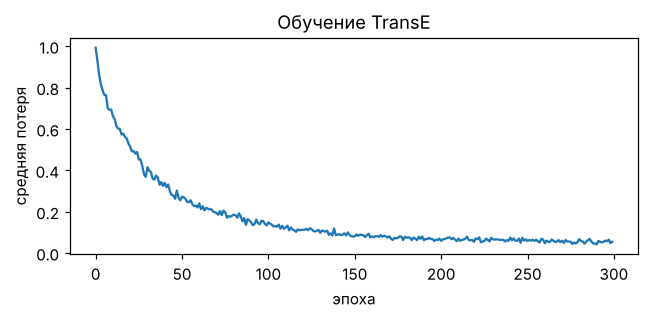

In [7]:
E = {name: i for i, name in enumerate(entities)}
R = {name: i for i, name in enumerate(relations)}

def encode(items):
    return np.array([(E[h], R[r], E[t]) for h, r, t in items], dtype=np.int64)

class TransE:
    def __init__(self, n_entities, n_relations, dim=32, seed=SEED):
        rng = np.random.default_rng(seed)
        bound = 6 / math.sqrt(dim)
        self.entity = normalize(rng.uniform(-bound, bound, (n_entities, dim)))
        self.relation = normalize(rng.uniform(-bound, bound, (n_relations, dim)))
        self.rng = rng

    def distance(self, h, r, t):
        return np.linalg.norm(self.entity[h] + self.relation[r] - self.entity[t], axis=-1)

    def fit(self, data, epochs=300, lr=0.02, margin=1.0, batch=128):
        losses = []
        n = len(self.entity)
        for _ in range(epochs):
            self.entity = normalize(self.entity)
            order = self.rng.permutation(len(data))
            total = 0.0
            for start in range(0, len(order), batch):
                pos = data[order[start : start + batch]]
                neg = pos.copy()
                corrupt_head = self.rng.random(len(neg)) < 0.5
                random_entities = self.rng.integers(0, n, len(neg))
                neg[corrupt_head, 0] = random_entities[corrupt_head]
                neg[~corrupt_head, 2] = random_entities[~corrupt_head]
                dp = self.entity[pos[:, 0]] + self.relation[pos[:, 1]] - self.entity[pos[:, 2]]
                dn = self.entity[neg[:, 0]] + self.relation[neg[:, 1]] - self.entity[neg[:, 2]]
                np_, nn = np.linalg.norm(dp, axis=1), np.linalg.norm(dn, axis=1)
                active = margin + np_ - nn > 0
                total += float(np.sum((margin + np_ - nn)[active]))
                gp = dp[active] / np.maximum(np_[active, None], 1e-9)
                gn = dn[active] / np.maximum(nn[active, None], 1e-9)
                pa, na = pos[active], neg[active]
                np.add.at(self.entity, pa[:, 0], -lr * gp)
                np.add.at(self.entity, pa[:, 2], lr * gp)
                np.add.at(self.relation, pa[:, 1], -lr * gp)
                np.add.at(self.entity, na[:, 0], lr * gn)
                np.add.at(self.entity, na[:, 2], -lr * gn)
                np.add.at(self.relation, na[:, 1], lr * gn)
            losses.append(total / len(data))
        self.entity = normalize(self.entity)
        return losses

fit_ids, eval_ids = encode(fit), encode(evaluation)
untrained = TransE(len(E), len(R))
model_eval = TransE(len(E), len(R))
losses = model_eval.fit(fit_ids)
print(f"Потери: эпоха 1 = {losses[0]:.3f}, эпоха {len(losses)} = {losses[-1]:.3f}")
plt.figure(figsize=(6, 3))
plt.plot(losses)
plt.xlabel("эпоха")
plt.ylabel("средняя потеря")
plt.title("Обучение TransE")
plt.tight_layout()
plt.savefig(RESULTS / "transe_loss.png", dpi=110)

## 5. Оценка: MR, MRR, Hits@N

Для каждого оценочного триплета заменяем голову, затем хвост на все сущности. Варианты, которые сами являются известными триплетами обучающей части (обучение + оценка), исключаются из ранжирования (filtered setting). Ранг — место исходного триплета. Для сравнения — та же оценка для необученной модели со случайными векторами.

In [8]:
known = set(map(tuple, encode(train_triples)))

def ranks(m, data):
    result = []
    for h, r, t in data:
        for side in (0, 2):
            if side == 2:
                scores = -m.distance(h, r, np.arange(len(E)))
                truth = t
                mask = [(h, r, x) in known and x != t for x in range(len(E))]
            else:
                scores = -m.distance(np.arange(len(E)), r, t)
                truth = h
                mask = [(x, r, t) in known and x != h for x in range(len(E))]
            scores = np.where(mask, -np.inf, scores)
            result.append(1 + int(np.sum(scores > scores[truth])))
    return np.array(result)

def rank_metrics(values):
    return {
        "MR": float(values.mean()),
        "MRR": float((1 / values).mean()),
        "Hits@1": float((values <= 1).mean()),
        "Hits@3": float((values <= 3).mean()),
        "Hits@10": float((values <= 10).mean()),
    }

trained_ranks = ranks(model_eval, eval_ids)
metrics = pd.DataFrame(
    {"TransE": rank_metrics(trained_ranks), "случайные векторы": rank_metrics(ranks(untrained, eval_ids))}
)
METRICS["ranking_eval"] = metrics.to_dict()
print(f"Оценочных триплетов: {len(eval_ids)}, рангов (голова и хвост): {len(trained_ranks)}, сущностей-кандидатов: {len(E)}")
print(metrics.round(3).to_string())

Оценочных триплетов: 255, рангов (голова и хвост): 510, сущностей-кандидатов: 465
         TransE  случайные векторы
MR       56.624            236.129
MRR       0.232              0.013
Hits@1    0.151              0.000
Hits@3    0.224              0.008
Hits@10   0.414              0.016


### Модель для прикладных задач

Метрики выше получены на модели, обученной только на первой части. Для кластеризации, классификации и предсказания связей модель с теми же параметрами и seed обучается заново на всей обучающей части (первая часть плюс оценочная). Скрытые триплеты `nearest_station` проверочных ячеек и типы объектов в неё по-прежнему не входят. Так прикладные результаты не зависят от того, какие связи ушли в оценку ради покрытия узлов.

In [9]:
train_ids = encode(train_triples)
model = TransE(len(E), len(R))
full_losses = model.fit(train_ids)
assert not set(map(tuple, train_ids)) & set(map(tuple, encode(link_test)))
print(f"Триплетов: {len(train_ids)}; потеря в последней эпохе {full_losses[-1]:.3f}")

Триплетов: 822; потеря в последней эпохе 0.104


## 6. Кластеризация

По практикуму кластеризация выполняется на всём датасете: векторы всех 294 объектов OSM. Ожидаемые классы — типы объектов, которых модель не видела. KMeans с k = 4; качество — Adjusted Rand Index. Для 2D-графиков векторы проецируются методом главных компонент.

ARI TransE = 0.002; ARI для случайных векторов = -0.002
кластер         0   1   2   3
тип                          
MetroEntrance   6   2  14  17
MetroStation    1   1   2   4
Park           28  24  27  75
Supermarket    15  15  22  41


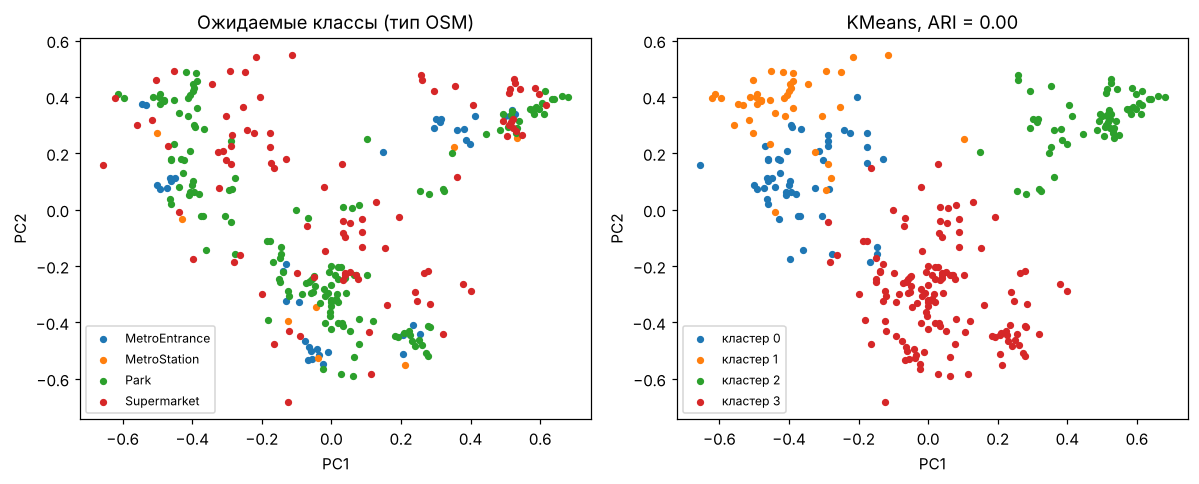

In [10]:
X = model.entity[[E[e] for e in features["entity"]]]
X_random = untrained.entity[[E[e] for e in features["entity"]]]
y = features["type"].to_numpy()
kmeans = KMeans(n_clusters=4, n_init=20, random_state=SEED).fit(X)
ari = adjusted_rand_score(y, kmeans.labels_)
ari_random = adjusted_rand_score(y, KMeans(n_clusters=4, n_init=20, random_state=SEED).fit(X_random).labels_)
METRICS["clustering"] = {"ARI_transe": ari, "ARI_random_vectors": ari_random}
print(f"ARI TransE = {ari:.3f}; ARI для случайных векторов = {ari_random:.3f}")
print(pd.crosstab(y, kmeans.labels_, rownames=["тип"], colnames=["кластер"]).to_string())

points = PCA(n_components=2, random_state=SEED).fit_transform(X)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for kind in sorted(set(y)):
    mask = y == kind
    axes[0].scatter(points[mask, 0], points[mask, 1], s=14, label=kind)
axes[0].set_title("Ожидаемые классы (тип OSM)")
axes[0].legend(fontsize=8)
for cluster in range(4):
    mask = kmeans.labels_ == cluster
    axes[1].scatter(points[mask, 0], points[mask, 1], s=14, label=f"кластер {cluster}")
axes[1].set_title(f"KMeans, ARI = {ari:.2f}")
axes[1].legend(fontsize=8)
for axis in axes:
    axis.set_xlabel("PC1")
    axis.set_ylabel("PC2")
plt.tight_layout()
plt.savefig(RESULTS / "clusters.png", dpi=110)

## 7. Классификация типа объекта (трансдуктивная)

Постановка **трансдуктивная**. Векторы TransE обучены на графе, где есть все 294 объекта, включая объекты проверочных ячеек и их связи (ячейка, название, вход → станция). Метки типа модель не видела, но структура тестовых объектов в обучение векторов вошла. Поэтому результат показывает, восстанавливается ли тип **известных графу** объектов по их связям. Это не точность для новых объектов, которых граф не содержал: для них у TransE нет векторов.

Признаки — векторы TransE. Обучение и проверка — по пространственному разбиению из раздела 1. Коэффициент регуляризации логистической регрессии выбирается только на обучающей части кросс-валидацией по ячейкам (GroupKFold), проверочная часть используется один раз.

Базовые модели:
- частый класс **обучающей** части — честная базовая модель;
- частый класс **проверочной** части, как в практикуме, — подсматривает в ответы и приведён только для сравнения;
- one-hot: те же связи объекта в обучающем графе, закодированные как мешок пар «отношение → объект», та же модель и тот же подбор.

In [11]:
train_mask = features["part"].to_numpy() == "train"
groups = features["cell"].to_numpy()

def fit_classifier(matrix):
    best = None
    for c in (0.1, 1.0, 10.0, 100.0):
        clf = LogisticRegression(C=c, max_iter=5000)
        folds = GroupKFold(n_splits=5)
        score = cross_val_score(clf, matrix[train_mask], y[train_mask], groups=groups[train_mask], cv=folds).mean()
        if best is None or score > best[0]:
            best = (score, c)
    clf = LogisticRegression(C=best[1], max_iter=5000).fit(matrix[train_mask], y[train_mask])
    prediction = clf.predict(matrix[~train_mask])
    return {
        "C": best[1],
        "cv_accuracy_train": float(best[0]),
        "test_accuracy": float(accuracy_score(y[~train_mask], prediction)),
        "test_macro_f1": float(f1_score(y[~train_mask], prediction, average="macro")),
    }

neighbours = defaultdict(set)
for h, r, t in train_triples:
    neighbours[h].add(f"{r}->{t}")
    neighbours[t].add(f"{r}<-{h}")
vocabulary = sorted({f for e in features["entity"] for f in neighbours[e]})
column = {name: i for i, name in enumerate(vocabulary)}
one_hot = np.zeros((len(features), len(vocabulary)))
for row, entity in enumerate(features["entity"]):
    for name in neighbours[entity]:
        one_hot[row, column[name]] = 1

train_major = Counter(y[train_mask]).most_common(1)[0][0]
test_major = Counter(y[~train_mask]).most_common(1)[0][0]
classification = {
    "majority_from_train": {"class": train_major, "test_accuracy": float(np.mean(y[~train_mask] == train_major))},
    "majority_from_test": {"class": test_major, "test_accuracy": float(np.mean(y[~train_mask] == test_major))},
    "one_hot": fit_classifier(one_hot),
    "transe": fit_classifier(X),
    "one_hot_columns": len(vocabulary),
    "setting": "transductive: test objects and their relations were in the embedding graph, labels were not",
}
METRICS["classification"] = classification
print(json.dumps(classification, ensure_ascii=False, indent=1))

{
 "majority_from_train": {
  "class": "Park",
  "test_accuracy": 0.46534653465346537
 },
 "majority_from_test": {
  "class": "Park",
  "test_accuracy": 0.46534653465346537
 },
 "one_hot": {
  "C": 10.0,
  "cv_accuracy_train": 0.8607287449392713,
  "test_accuracy": 0.7821782178217822,
  "test_macro_f1": 0.5669125826081267
 },
 "transe": {
  "C": 100.0,
  "cv_accuracy_train": 0.839136302294197,
  "test_accuracy": 0.7821782178217822,
  "test_macro_f1": 0.7866066137252579
 },
 "one_hot_columns": 410,
 "setting": "transductive: test objects and their relations were in the embedding graph, labels were not"
}


### Проверка: чем объясняется результат

Названия сетей и станций — сильная подсказка: «Дикси» почти наверняка супермаркет. Обучим TransE заново без отношения `has_name` и повторим классификацию. Так видно, сколько точности даёт пространственная структура сама по себе.

In [12]:
fit_no_name = encode([t for t in train_triples if t[1] != "has_name"])
model_no_name = TransE(len(E), len(R))
model_no_name.fit(fit_no_name)
X_no_name = model_no_name.entity[[E[e] for e in features["entity"]]]
ablation = fit_classifier(X_no_name)
METRICS["classification"]["transe_without_has_name"] = ablation
print(json.dumps(ablation, indent=1))

{
 "C": 1.0,
 "cv_accuracy_train": 0.5649122807017544,
 "test_accuracy": 0.49504950495049505,
 "test_macro_f1": 0.34771825396825395
}


## 8. Предсказание недостающих связей

Тип сущности — объекты проверочной части, связь — `nearest_station`. Эти триплеты не участвовали в обучении. Для каждого объекта хвост заменяется на каждую из восьми станций, варианты сортируются по оценке модели, фиксируется позиция верной станции. Базовые модели: случайный порядок (ожидаемый MRR = H₈ / 8), самая частая ближайшая станция в обучающей части и голосование соседей по графу: станции объектов обучающей части из соседних ячеек, упорядоченные по числу голосов.

In [13]:
relation = R["nearest_station"]
station_index = np.array([E[s] for s in station_ids])
train_nearest = Counter(t for h, r, t in train_triples if r == "nearest_station")
popular = [s for s, _ in train_nearest.most_common()] + [s for s in station_ids if s not in train_nearest]
nearest_of = {h: t for h, r, t in train_triples if r == "nearest_station"}
cell_of = dict(zip(features["entity"], features["cell"]))
members = defaultdict(list)
for entity, cell in cell_of.items():
    members[cell].append(entity)
adjacent = defaultdict(set)
for h, r, t in train_triples:
    if r.startswith("cell_"):
        adjacent[h].add(t)
        adjacent[t].add(h)

def neighbour_order(entity):
    votes = Counter(
        nearest_of[other]
        for cell in adjacent[cell_of[entity]]
        for other in members[cell]
        if other in nearest_of
    )
    return sorted(station_ids, key=lambda s: (-votes[s], popular.index(s)))

kind_of = dict(zip(features["entity"], features["type"]))
rows = []
for h, _, t in link_test:
    scores = -model.distance(E[h], relation, station_index)
    order = [station_ids[i] for i in np.argsort(-scores, kind="stable")]
    rows.append({
        "entity": h,
        "type": kind_of[h],
        "rank": order.index(t) + 1,
        "popular_rank": popular.index(t) + 1,
        "neighbour_rank": neighbour_order(h).index(t) + 1,
    })
link = pd.DataFrame(rows)

def link_scores(column):
    values = link[column]
    return {"MRR": float((1 / values).mean()), "Hits@1": float((values == 1).mean()), "Hits@3": float((values <= 3).mean()), "MR": float(values.mean())}

expected_random_mrr = sum(1 / k for k in range(1, len(station_ids) + 1)) / len(station_ids)
link_metrics = {
    "test_triples": len(link),
    "candidates": len(station_ids),
    "transe": link_scores("rank"),
    "most_frequent_station": link_scores("popular_rank"),
    "neighbour_cells_vote": link_scores("neighbour_rank"),
    "random_expected_MRR": expected_random_mrr,
    "transe_MRR_by_type": {k: float(v) for k, v in (1 / link["rank"]).groupby(link["type"]).mean().items()},
}
METRICS["link_prediction"] = link_metrics
print(json.dumps(link_metrics, ensure_ascii=False, indent=1))

{
 "test_triples": 97,
 "candidates": 8,
 "transe": {
  "MRR": 0.9587628865979382,
  "Hits@1": 0.9278350515463918,
  "Hits@3": 1.0,
  "MR": 1.1030927835051547
 },
 "most_frequent_station": {
  "MRR": 0.28457290132547863,
  "Hits@1": 0.08247422680412371,
  "Hits@3": 0.25773195876288657,
  "MR": 4.896907216494846
 },
 "neighbour_cells_vote": {
  "MRR": 0.8275036818851251,
  "Hits@1": 0.7216494845360825,
  "Hits@3": 0.8762886597938144,
  "MR": 1.597938144329897
 },
 "random_expected_MRR": 0.33973214285714287,
 "transe_MRR_by_type": {
  "MetroEntrance": 1.0,
  "Park": 0.9680851063829787,
  "Supermarket": 0.9074074074074074
 }
}


In [14]:
(RESULTS / "embedding_metrics.json").write_text(json.dumps(METRICS, ensure_ascii=False, indent=1) + "\n", encoding="utf-8")
print("Сохранено:", sorted(p.name for p in RESULTS.iterdir()))

Сохранено: ['clusters.png', 'embedding_metrics.json', 'transe_loss.png']


## 9. Выводы и ограничения

Числа ниже взяты из вывода ячеек этого запуска (seed 20261127, CPU). Повторный запуск дал те же значения.

- **Данные объявлений.** 11 квартир, 11 карточек, ни повторных наблюдений, ни подтверждённых дублей. Для обучения этого мало. Embedding обучен на 294 объектах OSM-части графа; на сайт результаты не переносятся.
- **Разбиение объектов.** 95 ячеек: 28 в проверке (101 объект) и 67 в обучении (193 объекта). Все четыре класса есть в обеих частях, станций метро — по 4.
- **Внутреннее разбиение триплетов.** Все 350 узлов 2-ядра есть и в обучающей, и в оценочной части. Вне критерия остались 115 узлов с единственной связью: 57 уникальных названий, 51 объект проверочных ячеек (их `nearest_station` скрыт), 2 объекта обучения и 5 ячеек. Их 114 триплетов только в обучении. В оценку ушло 255 из 822 триплетов (31%): каждому узлу ядра нужна хотя бы одна оценочная связь.
- **Ранжирование** модели, обученной на 567 триплетах: MR ≈ 57, MRR ≈ 0,23, Hits@10 ≈ 0,41 среди 465 кандидатов с фильтрацией. Случайные векторы: MR ≈ 236, MRR ≈ 0,01.
- **Кластеризация** векторов модели, обученной на всей обучающей части: ARI ≈ 0,002 при ≈ 0,00 у случайных векторов. Тип объекта в кластерах не выделяется: векторы кодируют положение. Это отрицательный результат.
- **Классификация типа, трансдуктивная.** TransE — точность 0,78, macro-F1 0,79. One-hot тех же связей — 0,78 и 0,57. Частый класс («парк») — 0,47, одинаково для обучающей и проверочной части. Без отношения `has_name` TransE даёт 0,50 при macro-F1 0,35, то есть почти базовый уровень. Векторы тестовых объектов обучены по их связям, поэтому это восстановление типа объектов, известных графу, а не классификация новых объектов. Основной вклад дают общие названия сетей и станций и связь входа со станцией.
- **Предсказание `nearest_station`** для 97 скрытых триплетов среди 8 станций: TransE — MRR ≈ 0,96, Hits@1 ≈ 0,93. Голосование соседних ячеек — 0,83, самая частая станция — 0,28, случайный порядок — 0,34. Для входов метро MRR = 1,0, потому что вход прямо связан со станцией через `entrance_of`.

Ограничения:
- практикум требует покрытия всех узлов; на графе с узлами степени 1 это невыполнимо, и критерий выполнен только для 2-ядра;
- ради покрытия в оценку ушла треть триплетов, поэтому метрики ранжирования ниже, чем при случайных 15%;
- прикладные задачи используют модель, переобученную на всей обучающей части с теми же параметрами;
- ближайшая станция вычислена по прямой на сфере, а не по пешеходной сети, как на сайте;
- задача о станции пространственно лёгкая: голосование соседей уже близко к модели;
- набор маленький — сотни сущностей, оценки по классу станций (4 объекта) неустойчивы;
- seed разбиения выбран по правилу о классах, без учёта качества модели; гиперпараметры TransE (размерность 32, 300 эпох, шаг 0,02, маржа 1) не подбирались;
- ноутбук выполнен скриптом `run_notebook.py`, а не ядром Jupyter. Код ячеек тот же; в Jupyter запуск не проверялся.